# Deploy the model

In [1]:
import os
import sys
import random
from matplotlib import pyplot as plt

sys.path.append(os.path.join(os.path.dirname(os.getcwd()), 'bin'))
from mrcnn import visualize
from mrcnn.model import log
import mrcnn.model as modellib

from shrubs import ShrubInferenceConfig, ShrubMapDataset
from shrubs import save_masks_as_geojson

Using TensorFlow backend.


## Configurations

In [2]:
%matplotlib inline 

ROOT = os.path.join(os.path.dirname(os.getcwd()))

# Directory with tiles to classify
TRAIN_DIR = os.path.join(ROOT, "data", "deployment_tiles")

# Directory to save logs and trained model
MODEL_DIR = os.path.join(ROOT, "data/logs")

MODEL_VERSION = 1

In [3]:
def get_ax(rows=1, cols=1, size=8):
    """Return a Matplotlib Axes array to be used in
    all visualizations in the notebook. Provide a
    central point to control graph sizes.
    
    Change the default size attribute to control the size
    of rendered images
    """
    _, ax = plt.subplots(rows, cols, figsize=(size*cols, size*rows))
    return ax

In [4]:
# Load images to classify
dataset = ShrubMapDataset()
dataset.load_dataset(TRAIN_DIR)
dataset.prepare()

In [5]:
inference_config = ShrubInferenceConfig()
# inference_config.display()

# Create model in testing mode
model = modellib.MaskRCNN(
    mode="inference",
    config=inference_config,
    model_dir=MODEL_DIR
)

# Get path to saved weights
# Either set a specific path or find last trained weights
model_path = os.path.join(MODEL_DIR, f"mask_rcnn_juniper_v{MODEL_VERSION}.h5")
# Or find the last trained weights
# model_path = model.find_last()

# Load trained weights
print("Loading weights from ", model_path)
model.load_weights(model_path, by_name=True)

Loading weights from  c:\IRANZO\shrubs-segmentation\data/logs\mask_rcnn_juniper_v1.h5


## Test classification

Pick a random image from the dataset and check the performance of the classification.

Ingest the image to the model and display the predictions.

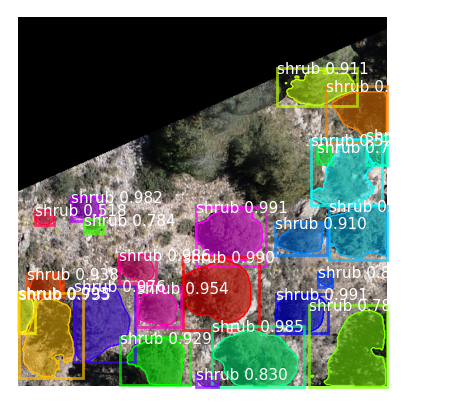

In [6]:
# Test on a random image
image_id = random.choice(dataset.image_ids)
original_image, image_meta, _, _, _ = modellib.load_image_gt(
    dataset,
    inference_config, 
    image_id,
    use_mini_mask=False
)

results = model.detect([original_image], verbose=False)

r = results[0]
visualize.display_instances(
    original_image,
    r['rois'],
    r['masks'],
    r['class_ids'], 
    dataset.class_names,
    r['scores'],
    ax=get_ax(size=5)
)

## Batch predictions

In [7]:
# Directory to store the predicted shrub masks
out_masks_dir = os.path.join(ROOT, "data", "deployment_tiles", "shrub_masks")

os.makedirs(out_masks_dir, exist_ok=True)

In [8]:
for image_id in dataset.image_ids:
    
    original_image, _, _, _, _ = modellib.load_image_gt(
        dataset,
        inference_config, 
        image_id,
        use_mini_mask=False
    )
    
    result = model.detect([original_image], verbose=False)[0]

    # Save shrub masks
    save_masks_as_geojson(
        img_id = image_id,
        masks = result["masks"],
        scores = result["scores"],
        class_ids = result["class_ids"],
        dataset = dataset,
        out_dir = out_masks_dir,
        min_area_pixels = 4
    )